# Notebook 4 - Univariate Analysis
Sprint 4 - EDA

Univariate analysis means studying one variable at a time. First I look at the numerical variables with statistics and plots, then at the categorical variables with frequencies and charts. I am not fixing any problem here, only observing and documenting.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only: TotalCharges converted to numbers
# (the 11 blank values become NaN and are simply ignored in the statistics)
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]

print("Numerical:", num_cols)
print("Categorical:", len(cat_cols), "columns (including Churn)")

Numerical: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: 17 columns (including Churn)


I created a copy called df_eda so the original data is not changed. Cleaning will be done properly in the preprocessing sprint.

# Part 1 - Numerical Variables

## 1.1 Mean, Median and Mode

**Concept:** These three are measures of central tendency, which describe the center of a variable. The mean is the average, the median is the middle value after sorting, and the mode is the most frequent value.

**Example (business):** Five employees earn 30k, 32k, 35k, 38k and 300k. The mean is 87k, but nobody earns near that. The median is 35k and describes a typical employee much better. So when the mean is far from the median, a few extreme values or a skewed shape is pulling the mean.

In [2]:
central = pd.DataFrame({
    "mean": df_eda[num_cols].mean(),
    "median": df_eda[num_cols].median(),
    "mode": [df_eda[c].mode()[0] for c in num_cols]
})
central.round(2)

,mean,median,mode
tenure,32.37,29.00,1.00
MonthlyCharges,64.76,70.35,20.05
TotalCharges,2283.30,1397.48,20.20


In [3]:
# how common is the mode?
for c in num_cols:
    top = df_eda[c].value_counts().head(3)
    print(c)
    print(top)
    print()

tenure
tenure
1     613
72    362
2     238
Name: count, dtype: int64

MonthlyCharges
MonthlyCharges
20.05    61
19.85    45
19.95    44
Name: count, dtype: int64

TotalCharges
TotalCharges
20.20    11
19.75     9
19.90     8
Name: count, dtype: int64



**What the code does:** The first cell calculates the mean, median and mode of the three numerical columns and puts them in one table. The second cell shows the three most repeated values of each column to see how strong the mode is.

**Why this method was used:** Comparing the three measures shows where the data is centered and also gives a first hint about the shape. If the mean and median are far apart, the distribution is skewed.

**What the output means:** For `tenure` the mean is about 32 months and the median is 29, and the mode is 1 month. For `MonthlyCharges` the mean is about 65 and the median is about 70, and the most common value is around 20. For `TotalCharges` the mean is about 2283 and the median is about 1397.

**Insights:** In `TotalCharges` the mean is much higher than the median, which means a group of long-term, high-paying customers pulls the average up, so the median is the better description of a typical customer. In `MonthlyCharges` the median is above the mean, and the mode near 20 suggests a big group of customers on the cheapest plans. The mode of `tenure` is 1, so many customers are brand new.

**Effect on the ML pipeline:** Differences between mean and median show skewed columns, which may need a transformation for models that assume a normal shape. Mean and median can also be used later to fill missing values, and here the median is the safer choice for `TotalCharges`.

## 1.2 Minimum, Maximum, Range, Variance and Standard Deviation

**Concept:** These measure the spread of the data. The range is maximum minus minimum. The variance is the average squared distance from the mean, and the standard deviation is the square root of the variance, so it has the same unit as the data.

**Example (numerical):** Two classes both have an average mark of 60. In class A marks go from 55 to 65, and in class B they go from 20 to 100. The averages are the same but class B has a much larger standard deviation, so the average alone hides the difference.

In [4]:
spread = pd.DataFrame({
    "min": df_eda[num_cols].min(),
    "max": df_eda[num_cols].max(),
    "range": df_eda[num_cols].max() - df_eda[num_cols].min(),
    "variance": df_eda[num_cols].var(),
    "std": df_eda[num_cols].std()
})
spread.round(2)

,min,max,range,variance,std
tenure,0.00,72.00,72.0,603.17,24.56
MonthlyCharges,18.25,118.75,100.5,905.41,30.09
TotalCharges,18.80,8684.80,8666.0,5138252.41,2266.77


In [5]:
# coefficient of variation = std / mean, to compare spread of columns with different units
(df_eda[num_cols].std() / df_eda[num_cols].mean()).round(2)

tenure            0.76
MonthlyCharges    0.46
TotalCharges      0.99
dtype: float64

**What the code does:** The code calculates minimum, maximum, range, variance and standard deviation for each numerical column. The second cell divides the standard deviation by the mean (coefficient of variation).

**Why this method was used:** Spread tells how much the values differ from each other. The coefficient of variation is useful because the three columns are in different units and ranges, so raw standard deviations cannot be compared directly.

**What the output means:** `tenure` goes from 0 to 72 (range 72) with a standard deviation of about 24.6. `MonthlyCharges` goes from about 18 to about 119 with a standard deviation of about 30. `TotalCharges` goes from about 19 to about 8685 with a standard deviation of about 2267.

**Insights:** The columns are on very different scales, with `TotalCharges` thousands of times larger than `tenure`. `TotalCharges` also has the highest relative spread, since its standard deviation is close to its mean. This is expected because it grows with tenure and with the monthly price.

**Effect on the ML pipeline:** Very different scales mean that scaling (standardization or min-max) is needed for distance based or gradient based models. Tree based models do not need it. The large spread of `TotalCharges` also suggests checking it for skewness.

## 1.3 Quartiles and Percentiles

**Concept:** Percentiles split sorted data into 100 parts. The 25th, 50th and 75th percentiles are the quartiles Q1, Q2 (median) and Q3. The difference Q3 minus Q1 is the interquartile range (IQR), which is the spread of the middle 50% of the data.

**Example (business):** If the 90th percentile of delivery time is 5 days, then 90% of orders arrive within 5 days. Companies use percentiles like this to promise service levels, because the average hides the slow deliveries.

In [6]:
percentiles = df_eda[num_cols].quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
print(percentiles.round(2))
print()

q1 = df_eda[num_cols].quantile(0.25)
q3 = df_eda[num_cols].quantile(0.75)
print("IQR:")
print((q3 - q1).round(2))

      tenure  MonthlyCharges  TotalCharges
0.01     1.0           19.20         19.90
0.05     1.0           19.65         49.60
0.10     2.0           20.05         84.60
0.25     9.0           35.50        401.45
0.50    29.0           70.35       1397.48
0.75    55.0           89.85       3794.74
0.90    69.0          102.60       5976.64
0.95    72.0          107.40       6923.59
0.99    72.0          114.73       8039.88

IQR:
tenure              46.00
MonthlyCharges      54.35
TotalCharges      3393.29
dtype: float64


**What the code does:** `quantile` is used with a list of probabilities to get the 1st, 5th, 10th, 25th, 50th, 75th, 90th, 95th and 99th percentiles. The IQR is calculated as Q3 minus Q1.

**Why this method was used:** Percentiles are not affected by extreme values the way the mean is, and they show how the values are spread across the range. The IQR will also be used later for outlier detection.

**What the output means:** For `tenure` the quartiles are about 9, 29 and 55 months. For `MonthlyCharges` they are about 35.5, 70.4 and 89.9. For `TotalCharges` they are about 401, 1397 and 3795. The 99th percentile of each column is still close to the maximum.

**Insights:** A quarter of customers have a tenure of 9 months or less, so there are many new customers. The gap between the 99th percentile and the maximum is small, so there is no sign of extreme values far away from the rest. For `TotalCharges` the distance from Q3 to the maximum is much larger than from the minimum to Q1, which is the sign of a right tail.

**Effect on the ML pipeline:** The IQR from this step is used in the outlier notebook. Percentiles can also be used for binning (for example tenure groups) during feature engineering.

## 1.4 Skewness and Kurtosis

**Concept:** Skewness measures the asymmetry of a distribution. A value near 0 is symmetric, a positive value means a longer tail on the right, and a negative value means a longer tail on the left. Kurtosis measures how heavy the tails are or how peaked the shape is. In pandas, `kurt()` gives excess kurtosis, where 0 is like a normal curve, positive means heavier tails and negative means a flatter shape with lighter tails.

**Example (AI/ML):** House prices usually have a positive skew, because a few very expensive houses stretch the right side. Many models work better after a log transformation that makes the shape more symmetric.

In [7]:
shape_stats = pd.DataFrame({
    "skewness": df_eda[num_cols].skew(),
    "kurtosis": df_eda[num_cols].kurt()
})
shape_stats.round(2)

,skewness,kurtosis
tenure,0.24,-1.39
MonthlyCharges,-0.22,-1.26
TotalCharges,0.96,-0.23


**What the code does:** `skew()` and `kurt()` calculate the skewness and the excess kurtosis of each numerical column.

**Why this method was used:** The mean and the median only give a hint about the shape. Skewness and kurtosis put a number on it, so I can compare columns.

**What the output means:** `tenure` has a small positive skew of about 0.24, `MonthlyCharges` has a small negative skew of about -0.22, and `TotalCharges` has a clear positive skew of about 0.96. The kurtosis of `tenure` and `MonthlyCharges` is clearly negative (around -1.4 and -1.3), while for `TotalCharges` it is close to -0.2.

**Insights:** `TotalCharges` is moderately right skewed, as the mean greater than median suggested. The strongly negative kurtosis of `tenure` and `MonthlyCharges` means they are flatter than a normal curve with light tails, which usually means several groups or a spread out shape rather than one bell. The plots in the next section will show why.

**Effect on the ML pipeline:** A transformation such as log or square root could be tested for `TotalCharges` if the chosen model is sensitive to skew. The skewness values also show that none of the columns is normally distributed, which matters for models and tests that assume normality.

## 1.5 Histogram

**Concept:** A histogram divides the range of a numerical variable into bins and shows how many values fall in each bin. It shows the shape: where the values are concentrated, whether there is one peak or more, and whether the data is skewed.

**Example (business):** A histogram of customer ages in a shop shows if most customers are young, or if there are two groups, for example students and middle aged shoppers.

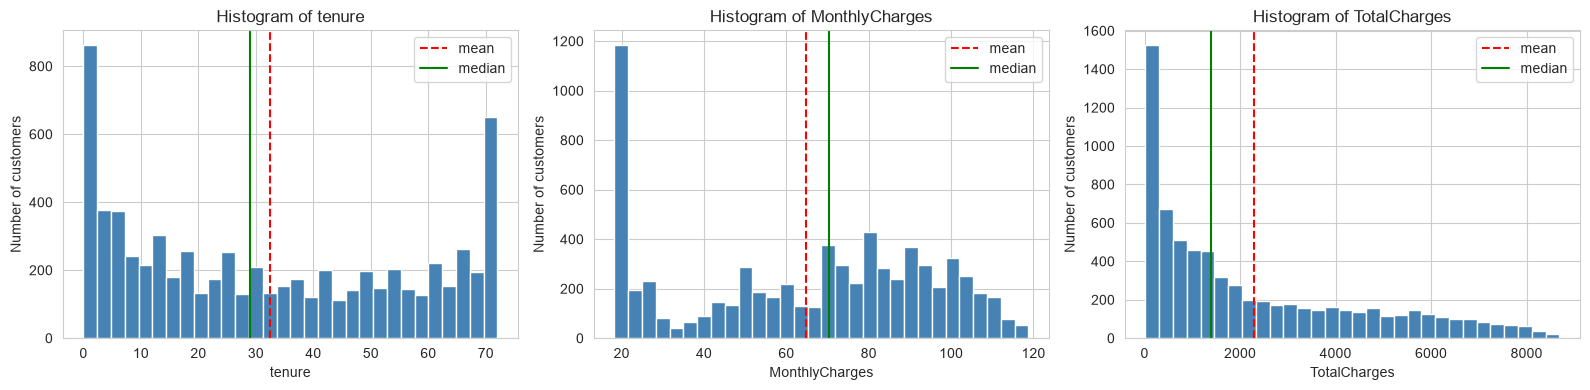

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, num_cols):
    ax.hist(df_eda[col].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.axvline(df_eda[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df_eda[col].median(), color="green", linestyle="-", label="median")
    ax.set_title("Histogram of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
    ax.legend()

plt.tight_layout()
plt.show()

**What the code does:** It draws one histogram with 30 bins for each numerical column, and adds a dashed line for the mean and a solid line for the median.

**Why this method was used:** A histogram is the basic plot for the shape of a numerical variable, and the two lines show how the center measures compare with the shape.

**What the output means:** The `tenure` histogram has tall bars at both ends, a very high bar near 0 to 2 months and another at about 72 months, with a flatter middle. `MonthlyCharges` has a very large spike at the low end near 20, and then a wide group between 60 and 110. `TotalCharges` has a tall bar near 0 and then the bars decrease steadily to the right.

**Insights:** `tenure` is not bell shaped, it looks U shaped: many new customers and many very loyal customers, with fewer in between. The spike in `MonthlyCharges` near 20 is probably the customers who only have phone service and no internet, which I can test in the bivariate notebook. The shape of `TotalCharges` is the result of many customers being new or having low charges.

**Effect on the ML pipeline:** None of the three numerical features is normal, so I should not assume normality. The U shape of `tenure` and the spike in `MonthlyCharges` show that there are different customer groups, which could be captured by binning or by features like InternetService.

## 1.6 KDE (Density) Plot

**Concept:** A KDE plot is a smooth version of the histogram. It estimates the probability density curve, so the shape does not depend on the choice of bin width. The area under the curve is 1.

**Example (numerical):** If I draw the heights of 1000 people, the histogram bars change as I change the number of bins, but the KDE curve gives a stable smooth shape with the peak clearly visible.

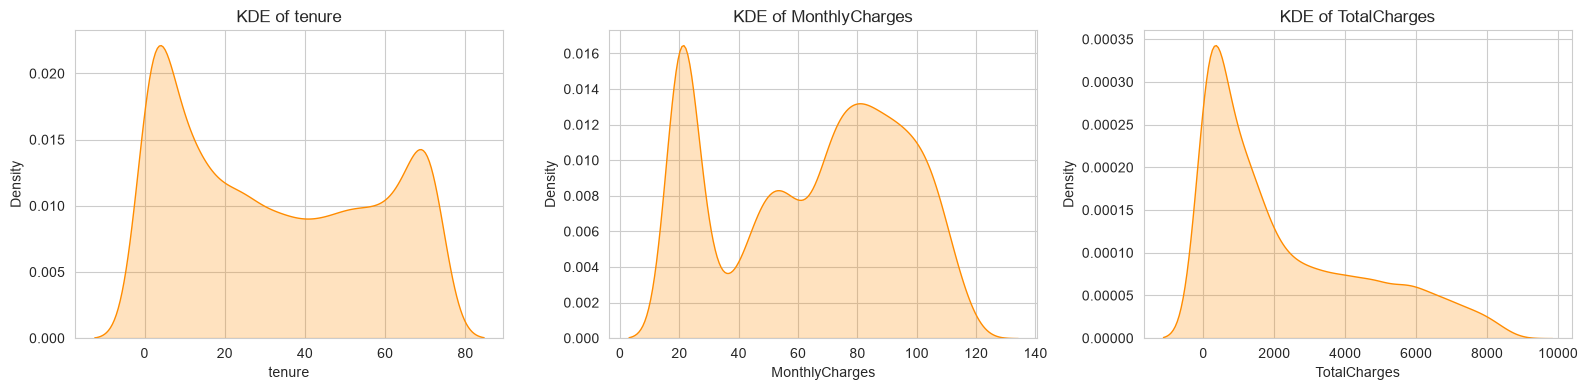

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, num_cols):
    sns.kdeplot(df_eda[col].dropna(), fill=True, color="darkorange", ax=ax)
    ax.set_title("KDE of " + col)
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

**What the code does:** `sns.kdeplot` draws a smooth density curve for each numerical column, with the area filled in.

**Why this method was used:** The KDE removes the effect of the bin choice and makes the peaks easier to count, so it is a good partner for the histogram.

**What the output means:** `tenure` shows two peaks, one near the start and one near the end of the range. `MonthlyCharges` shows a sharp peak near 20 and a broader hump around 80 to 90. `TotalCharges` has one peak near zero and a long tail to the right.

**Insights:** Both `tenure` and `MonthlyCharges` are multimodal (more than one peak), which supports the idea of different customer groups mixed together. `TotalCharges` is clearly right skewed. Note that the KDE curve can extend slightly beyond the real range, for example below 0, which is only a smoothing effect.

**Effect on the ML pipeline:** Multimodal columns are poorly described by a single mean, so group based features could help the model. For the skewed `TotalCharges`, a log transform could make it more symmetric.

## 1.7 Box Plot

**Concept:** A box plot summarizes a variable with five numbers: minimum, Q1, median, Q3 and maximum. The box is the IQR, the line inside the box is the median, and the whiskers extend to the furthest points within 1.5 times the IQR. Points beyond the whiskers are shown as dots and are potential outliers.

**Example (business):** Comparing the delivery times of a courier with a box plot immediately shows the typical time (the box), and the unusually late deliveries (the dots).

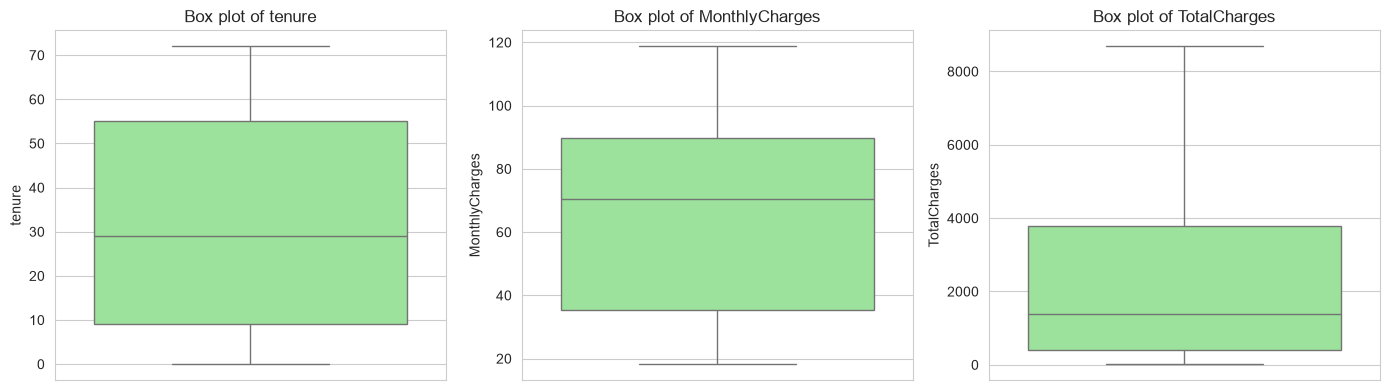

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_eda[col], color="lightgreen", ax=ax)
    ax.set_title("Box plot of " + col)

plt.tight_layout()
plt.show()

In [11]:
# count of points beyond the 1.5 x IQR whiskers
for col in num_cols:
    q1 = df_eda[col].quantile(0.25)
    q3 = df_eda[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = ((df_eda[col] < low) | (df_eda[col] > high)).sum()
    print(col, "-> lower limit:", round(low, 2), "upper limit:", round(high, 2), "points outside:", n_out)

tenure -> lower limit: -60.0 upper limit: 124.0 points outside: 0
MonthlyCharges -> lower limit: -46.02 upper limit: 171.38 points outside: 0
TotalCharges -> lower limit: -4688.48 upper limit: 8884.67 points outside: 0


**What the code does:** The first cell draws a box plot for each numerical column. The second cell calculates the whisker limits (Q1 minus 1.5 IQR and Q3 plus 1.5 IQR) and counts the points outside them.

**Why this method was used:** A box plot shows the median, the spread and the possible outliers in one picture, and the count confirms what the plot shows.

**What the output means:** The three box plots show no dots beyond the whiskers, and the count of points outside the limits is 0 for all three columns. The median of `tenure` is lower than the middle of the box range, and for `TotalCharges` the box is pushed toward the bottom with a long upper whisker.

**Insights:** There are no outliers by the IQR rule in any numerical column, even though `TotalCharges` is right skewed. The skew is a long tail, not isolated extreme points. This will be checked again in the outlier notebook with other methods.

**Effect on the ML pipeline:** No outlier removal is needed for these columns according to this check, so no data is lost. The box plots also confirm which columns are skewed.

# Part 2 - Categorical Variables

## 2.1 Unique values, frequency, value counts and percentage distribution

**Concept:** For a categorical variable I look at how many unique categories it has (cardinality), how many times each appears (frequency) and what share each has (percentage). `value_counts()` gives the frequency and `normalize=True` gives the percentage.

**Example (business):** A shop sells through UPI, card and cash. If UPI is 70% of the payments, the shop knows which payment system must never fail, and it can also see that cash is rare.

In [12]:
# unique values per categorical column
print(df[cat_cols].nunique().sort_values())

gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
PaperlessBilling    2
Churn               2
InternetService     3
OnlineSecurity      3
OnlineBackup        3
TechSupport         3
DeviceProtection    3
StreamingTV         3
StreamingMovies     3
Contract            3
MultipleLines       3
PaymentMethod       4
dtype: int64


In [13]:
# frequency and percentage for each categorical column
for col in cat_cols:
    counts = df[col].value_counts()
    percent = (df[col].value_counts(normalize=True) * 100).round(1)
    table = pd.DataFrame({"count": counts, "percent": percent})
    print(col)
    print(table)
    print()

gender
        count  percent
gender                
Male     3555     50.5
Female   3488     49.5

SeniorCitizen
               count  percent
SeniorCitizen                
0               5901     83.8
1               1142     16.2

Partner
         count  percent
Partner                
No        3641     51.7
Yes       3402     48.3

Dependents
            count  percent
Dependents                
No           4933     70.0
Yes          2110     30.0

PhoneService
              count  percent
PhoneService                
Yes            6361     90.3
No              682      9.7

MultipleLines
                  count  percent
MultipleLines                   
No                 3390     48.1
Yes                2971     42.2
No phone service    682      9.7

InternetService
                 count  percent
InternetService                
Fiber optic       3096     44.0
DSL               2421     34.4
No                1526     21.7

OnlineSecurity
                     count  percent
On

**What the code does:** `nunique()` counts the categories of every categorical column. The loop then builds a small table with the count and the percentage of each category for every column.

**Why this method was used:** The frequency table is the standard way to understand a categorical variable. Printing all of them in a loop makes sure I do not skip any column.

**What the output means:** All categorical columns have between 2 and 4 categories. Some of the main shares: Month-to-month contracts are about 55% of customers, two year about 24% and one year about 21%. Fiber optic is about 44%, DSL about 34% and no internet about 22%. Senior citizens are about 16%. Phone service is taken by about 90%. Paperless billing is used by about 59%. Gender is almost 50 and 50. The target Churn is about 73.5% No and 26.5% Yes.

**Insights:** The customer base is mostly on flexible month-to-month contracts and mostly uses fiber or DSL internet. Senior citizens are a small group. Gender is balanced, so it is unlikely to be an important feature. There are no rare categories, since the smallest category still has hundreds of customers. The target is imbalanced.

**Effect on the ML pipeline:** All columns have low cardinality, so one-hot encoding is safe and will not create too many columns. The imbalance of Churn has to be considered in model training and evaluation. Gender with an almost equal split carries little signal on its own.

## 2.2 Bar Chart and Count Plot

**Concept:** A bar chart shows the frequency of each category as the height of a bar. A count plot in seaborn is a bar chart that counts the rows of each category automatically. Bars are good for comparing the sizes of categories.

**Example (business):** A bar chart of orders per product category shows at once which category sells the most and which sells the least.

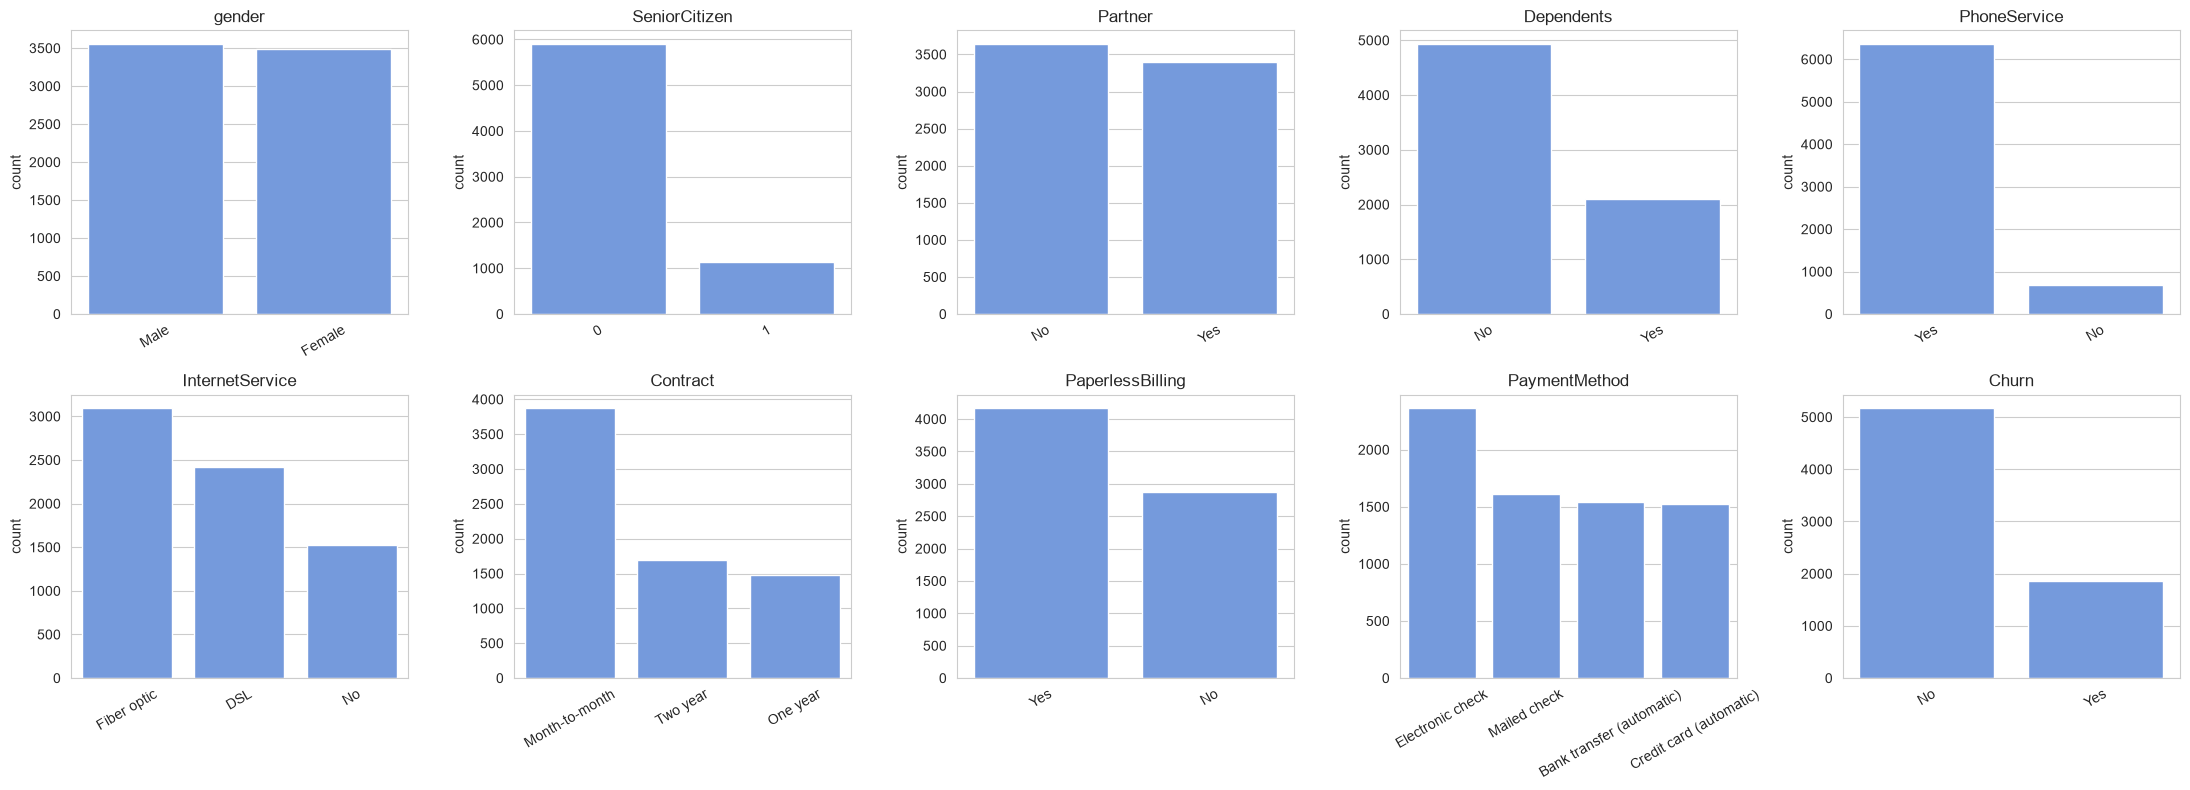

In [14]:
plot_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "InternetService",
             "Contract", "PaperlessBilling", "PaymentMethod", "Churn"]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, color="cornflowerblue", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**What the code does:** It draws count plots for ten important categorical columns in a grid, with the bars sorted from the largest to the smallest category.

**Why this method was used:** A count plot is the simplest way to compare category sizes, and sorting the bars makes the ranking easy to read. I selected the ten columns that describe the customer, the service and the contract, and left out the six add-on columns to keep the plot readable.

**What the output means:** Each bar is the number of customers in that category. In Contract the Month-to-month bar is the tallest. In InternetService Fiber optic is the tallest. In PaymentMethod Electronic check is the largest and the other three are close to each other. In Churn the No bar is almost three times as tall as the Yes bar.

**Insights:** The Partner split is close to half and half, and only about 30 percent of customers have dependents, so many customers are individuals or couples without children, and a large share pays by electronic check. Electronic check, month-to-month and fiber are the biggest groups, so I will check in the bivariate notebook whether these groups have higher churn.

**Effect on the ML pipeline:** The plots show which categories are small and which are large, which helps to decide how to group or encode them. They also confirm that the target is imbalanced.

## 2.3 Pie Chart

**Concept:** A pie chart shows the share of each category as a slice of a circle. It works only when there are few categories (2 to 4) and when the goal is to show parts of a whole. With many categories, or when slices are similar, a bar chart is easier to read.

**Example (business):** A pie chart of a company revenue split between three regions shows each region share of the total at a glance.

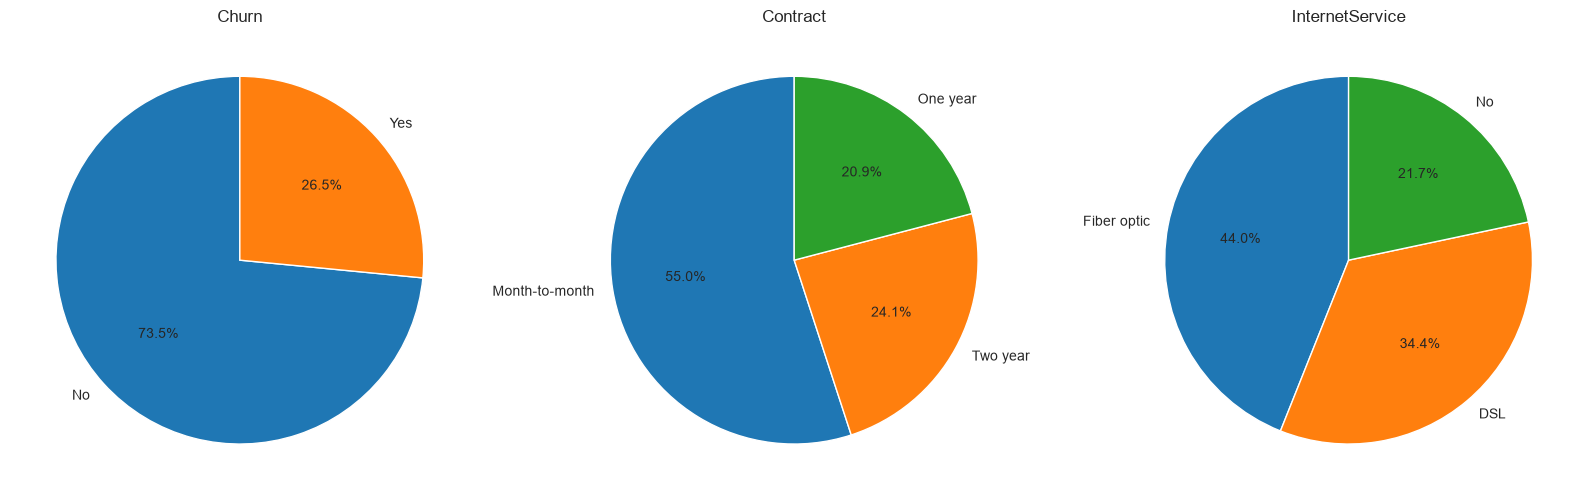

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ["Churn", "Contract", "InternetService"]):
    counts = df[col].value_counts()
    ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(col)

plt.tight_layout()
plt.show()

**What the code does:** It draws a pie chart with percentage labels for Churn, Contract and InternetService.

**Why this method was used:** These three columns have only two or three categories, so a pie chart is readable. I did not use it for PaymentMethod or for the add-on columns, because a bar chart compares them better.

**What the output means:** The Churn pie shows about 73.5% of customers staying and about 26.5% leaving. The Contract pie shows month-to-month as a bit more than half of the customers. The InternetService pie shows fiber optic as the biggest slice and no internet as the smallest.

**Insights:** More than one in four customers has churned, which is a high rate for a subscription business. More than half of the customers can leave at any time because they are on month-to-month contracts.

**Effect on the ML pipeline:** The share of the minority class sets the baseline for the model. If a model cannot do better than predicting the majority class, it is not useful. The contract structure also suggests Contract will be an important feature.

# Part 3 - Findings for Each Important Variable

| Variable | Finding |
|---|---|
| tenure | Mean about 32, median 29, range 0 to 72. Slight right skew. U shaped, many new customers (mode is 1 month) and many loyal customers near 72 months. No outliers by IQR |
| MonthlyCharges | Mean about 65, median about 70, range about 18 to 119. Slight left skew. Large spike near 20 and a second group near 80 to 90, so it is multimodal. No outliers by IQR |
| TotalCharges | Mean about 2283, median about 1397. Clear right skew of about 0.96. Highest relative spread. 11 missing values because of tenure 0. No outliers by IQR |
| Contract | Month-to-month is about 55%, so most customers are not locked in |
| InternetService | Fiber optic about 44%, DSL about 34%, none about 22% |
| PaymentMethod | Electronic check is the largest group |
| SeniorCitizen | About 16% of customers, a small segment |
| gender | Almost equal split, likely a weak feature |
| Churn | About 26.5% churned, so the target is imbalanced |

# Summary

- The three numerical features are not normally distributed. `tenure` and `MonthlyCharges` are multimodal and `TotalCharges` is right skewed.
- No numerical column has points outside the IQR whiskers.
- All categorical features have low cardinality and no rare categories.
- The target Churn is imbalanced.

**Points for later sprints**
1. Scale the numerical columns because their ranges are very different.
2. Consider a log transform for `TotalCharges`.
3. Consider grouping `tenure` into bands.
4. Handle the class imbalance of Churn.
5. Encode the categorical columns with one-hot encoding.

**What I learned:** Statistics such as the mean can be misleading when the shape is not a single bell. The histogram and KDE showed that tenure and monthly charges contain different customer groups, which a single average cannot show.

Next: `05_Bivariate_Analysis.ipynb`